# Banking Customer Intelligence & Retention\n## Exploratory analysis and model-governance review\n\n**Author:** Chico Mkandawire  \n**Scenario:** Nyanja Commercial Bank — Malawi  \n**Currency:** MWK\n\nThis executable notebook is the analytical companion to the deployed Streamlit Command Centre. It explores the customer cohort, renders portfolio charts and reviews current model-governance evidence from the canonical training artefacts.\n\n**[Open this notebook in Google Colab](https://colab.research.google.com/github/MkandawireChico/-Banking-Customer-Churn-Analysis-and-Prediction/blob/main/notebooks/customer_churn_analysis.ipynb)**. In Colab, run all cells from top to bottom. The setup cell clones the repository and installs its requirements; subsequent cells load the committed artefacts and generate the tables and charts.\n\n**Source of truth:** `scripts/train_pipeline.py` owns data cleaning, feature preparation, model selection, calibration, evaluation and artefact generation. This notebook deliberately does not implement a second training pipeline or hard-code historical model metrics.\n\n> **Data note:** customer records and outcomes are synthetic and created for a controlled portfolio demonstration. They are not real bank customers or operational bank records.

## 1. Environment and project paths

The first code cell clones the repository and installs its dependencies. It then creates the synthetic dataset and runs the repository's canonical training pipeline **only when the required local artefacts are missing**. This is necessary because generated CSV and model files are deliberately excluded from Git.

The notebook works when launched from either the repository root or the `notebooks/` directory. The training step may take several minutes in a fresh Colab runtime.


In [9]:
import os
import subprocess
import sys
from pathlib import Path

# Google Colab starts in /content. Clone the project once per fresh runtime.
PROJECT_DIR = Path('/content/-Banking-Customer-Churn-Analysis-and-Prediction')
if not PROJECT_DIR.exists():
    subprocess.run([
        'git', 'clone',
        'https://github.com/MkandawireChico/-Banking-Customer-Churn-Analysis-and-Prediction.git',
        str(PROJECT_DIR),
    ], check=True)

os.chdir(PROJECT_DIR)
subprocess.run([sys.executable, '-m', 'pip', 'install', '-r', 'requirements.txt'], check=True)

# The generated data and model artefacts are intentionally excluded from Git.
# Create them in this Colab runtime before the analysis cells try to load them.
raw_path = PROJECT_DIR / 'data/raw/churn_customers_synthetic.csv'
if not raw_path.exists():
    subprocess.run([sys.executable, 'scripts/generate_dataset.py'], check=True, cwd=PROJECT_DIR)

required_artifacts = [
    PROJECT_DIR / 'data/processed/churn_customers_clean.csv',
    PROJECT_DIR / 'data/processed/churn_predictions.csv',
    PROJECT_DIR / 'data/processed/churn_customer_scores.csv',
    PROJECT_DIR / 'models/logistic_regression_pipeline.joblib',
]
if not all(path.exists() for path in required_artifacts):
    print('Project artefacts are missing. Running the canonical training pipeline...')
    subprocess.run([sys.executable, 'scripts/train_pipeline.py'], check=True, cwd=PROJECT_DIR)

missing = [str(path.relative_to(PROJECT_DIR)) for path in [raw_path, *required_artifacts] if not path.exists()]
if missing:
    raise FileNotFoundError('Setup did not create required artefacts: ' + ', '.join(missing))

print(f'Project ready at: {PROJECT_DIR}')
print('Dataset and model artefacts are ready. Continue running the notebook cells in order.')


Project ready at: /content/-Banking-Customer-Churn-Analysis-and-Prediction
Dataset and model artefacts are ready. Continue running the notebook cells in order.


In [10]:
from pathlib import Path
import json
import warnings

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

warnings.filterwarnings("ignore", category=FutureWarning)

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "data").exists() and (PROJECT_ROOT.parent / "data").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

RAW_PATH = PROJECT_ROOT / "data/raw/churn_customers_synthetic.csv"
CLEAN_PATH = PROJECT_ROOT / "data/processed/churn_customers_clean.csv"
TEST_PATH = PROJECT_ROOT / "data/processed/churn_predictions.csv"
PORTFOLIO_PATH = PROJECT_ROOT / "data/processed/churn_customer_scores.csv"
MODEL_PATH = PROJECT_ROOT / "models/logistic_regression_pipeline.joblib"
CHART_DIR = PROJECT_ROOT / "visuals/charts"
CHART_DIR.mkdir(parents=True, exist_ok=True)

required_paths = [RAW_PATH, CLEAN_PATH, TEST_PATH, PORTFOLIO_PATH, MODEL_PATH]
missing_paths = [str(path.relative_to(PROJECT_ROOT)) for path in required_paths if not path.exists()]
if missing_paths:
    raise FileNotFoundError(
        "Required project artefacts are missing: "
        + ", ".join(missing_paths)
        + ". Run the generator and training pipeline first."
    )

print(f"Project root: {PROJECT_ROOT}")

Project root: /content/-Banking-Customer-Churn-Analysis-and-Prediction


## 2. Load canonical project artefacts

The raw cohort is useful for data-quality inspection. The cleaned cohort supports descriptive analysis. The test predictions and full-population scores have different analytical purposes and are kept separate throughout.

In [11]:
raw = pd.read_csv(RAW_PATH)
customers = pd.read_csv(CLEAN_PATH)
test_predictions = pd.read_csv(TEST_PATH)
portfolio_scores = pd.read_csv(PORTFOLIO_PATH)

model_bundle = joblib.load(MODEL_PATH)
model_metadata = model_bundle.get("metadata", {})

print(f"Raw cohort: {raw.shape[0]:,} rows × {raw.shape[1]:,} columns")
print(f"Clean cohort: {customers.shape[0]:,} rows × {customers.shape[1]:,} columns")
print(f"Held-out test predictions: {len(test_predictions):,}")
print(f"Full-population scores: {len(portfolio_scores):,}")
print(f"Saved model type: {model_bundle.get('model_type', 'not recorded')}")
print(f"Calibration: {model_metadata.get('calibration_method', 'not recorded')}")

Raw cohort: 20,200 rows × 27 columns
Clean cohort: 20,000 rows × 27 columns
Held-out test predictions: 5,000
Full-population scores: 20,000
Saved model type: logistic
Calibration: sigmoid


/usr/local/lib/python3.13/dist-packages/sklearn/base.py:380: InconsistentVersionWarning: Trying to unpickle estimator SimpleImputer from version 1.9.1 when using version 1.6.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/base.py:380: InconsistentVersionWarning: Trying to unpickle estimator StandardScaler from version 1.9.1 when using version 1.6.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/base.py:380: InconsistentVersionWarning: Trying to unpickle estimator Pipeline from version 1.9.1 when using version 1.6.1. This might lead to breaking code or invalid

## 3. Data integrity and quality review

The generator deliberately injects data-quality issues. The training pipeline standardises categories, enforces one row per customer, treats implausible values as missing and leaves imputation to the fitted preprocessing pipeline.

The checks below make the input quality visible without silently modifying the canonical source files.

In [12]:
quality_summary = pd.DataFrame({
    "Check": [
        "Exact duplicate raw rows",
        "Duplicate raw customer IDs",
        "Missing raw cells",
        "Duplicate cleaned customer IDs",
        "Missing cleaned cells",
        "Implausible cleaned ages (<18 or >90)",
        "Negative cleaned monthly transactions",
    ],
    "Count": [
        int(raw.duplicated().sum()),
        int(raw["Customer_ID"].duplicated().sum()),
        int(raw.isna().sum().sum()),
        int(customers["Customer_ID"].duplicated().sum()),
        int(customers.isna().sum().sum()),
        int(((customers["Age"] < 18) | (customers["Age"] > 90)).sum()),
        int((customers["Average_Monthly_Transactions"] < 0).sum()),
    ],
})
display(quality_summary)

assert customers["Customer_ID"].is_unique, "Clean cohort must contain one row per customer."
assert test_predictions["Customer_ID"].is_unique, "Test predictions must be unique by customer."
assert portfolio_scores["Customer_ID"].is_unique, "Portfolio scores must be unique by customer."

,Check,Count
0,Exact duplicate raw rows,182
1,Duplicate raw customer IDs,200
2,Missing raw cells,1011
3,Duplicate cleaned customer IDs,0
4,Missing cleaned cells,1097
5,Implausible cleaned ages (<18 or >90),0
6,Negative cleaned monthly transactions,0


,Missing values
Monthly_Income,404
Marital_Status,304
Has_Internet_Banking,303


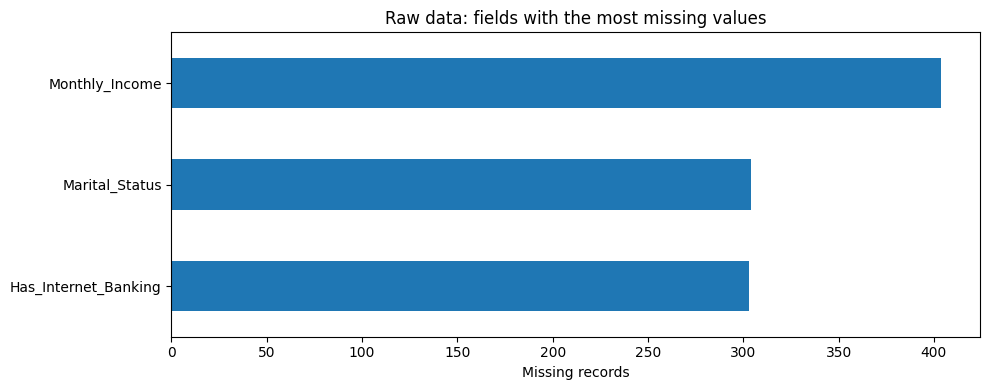

In [13]:
missing = raw.isna().sum().sort_values(ascending=False)
missing = missing[missing > 0]

if not missing.empty:
    display(missing.rename("Missing values").to_frame())
else:
    print("No missing values found in the raw cohort.")

fig, ax = plt.subplots(figsize=(10, 4))
if not missing.empty:
    missing.head(15).sort_values().plot(kind="barh", ax=ax)
    ax.set_title("Raw data: fields with the most missing values")
    ax.set_xlabel("Missing records")
else:
    ax.text(0.5, 0.5, "No missing values", ha="center", va="center")
    ax.set_axis_off()
plt.tight_layout()
plt.show()

## 4. Portfolio profile

These summaries describe the generated customer population. Monetary values are shown in MWK. They are descriptive portfolio statistics, not audited bank financials.

In [14]:
portfolio_summary = pd.Series({
    "Customers": len(customers),
    "Observed churned customers": int(customers["Churn"].sum()),
    "Observed churn rate": customers["Churn"].mean(),
    "Average account tenure (months)": customers["Account_Tenure_Months"].mean(),
    "Average monthly balance (MWK)": customers["Average_Monthly_Balance"].mean(),
    "Median monthly balance (MWK)": customers["Average_Monthly_Balance"].median(),
})
display(portfolio_summary.to_frame("Value").style.format({
    "Value": lambda value: f"{value:,.2f}" if isinstance(value, (int, float, np.number)) else value
}))

,Value
Customers,"20,000.00"
Observed churned customers,"2,509.00"
Observed churn rate,0.13
Average account tenure (months),39.94
Average monthly balance (MWK),"607,412.88"
Median monthly balance (MWK),"428,000.00"


,Customers,Churned,Churn_Rate,Avg_Balance_MWK
Customer_Segment,,,,
Student/Youth,"1,957",268,13.7%,"MWK 178,173"
Salary Account,"6,021",774,12.9%,"MWK 490,786"
Retail,"7,113",879,12.4%,"MWK 433,806"
Premium,"2,009",241,12.0%,"MWK 1,654,518"
SME,"2,900",347,12.0%,"MWK 839,643"


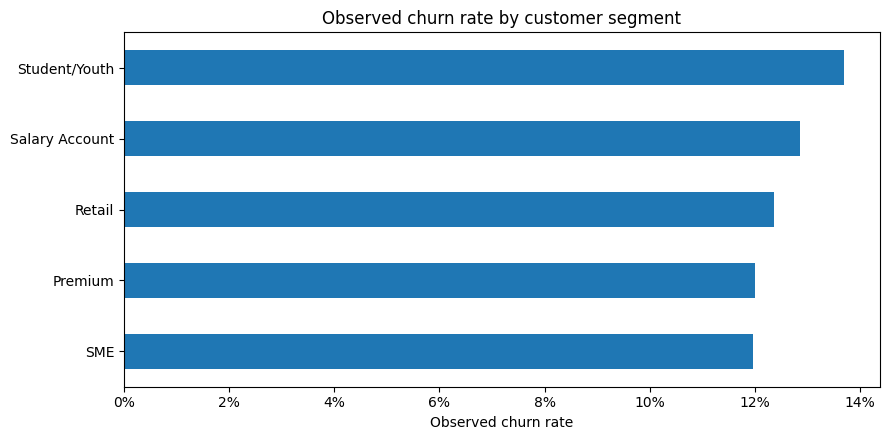

In [15]:
segment_summary = (
    customers.groupby("Customer_Segment", observed=True)
    .agg(
        Customers=("Customer_ID", "nunique"),
        Churned=("Churn", "sum"),
        Churn_Rate=("Churn", "mean"),
        Avg_Balance_MWK=("Average_Monthly_Balance", "mean"),
    )
    .sort_values("Churn_Rate", ascending=False)
)
display(segment_summary.style.format({
    "Customers": "{:,.0f}",
    "Churned": "{:,.0f}",
    "Churn_Rate": "{:.1%}",
    "Avg_Balance_MWK": "MWK {:,.0f}",
}))

fig, ax = plt.subplots(figsize=(9, 4.5))
segment_summary["Churn_Rate"].sort_values().plot(kind="barh", ax=ax)
ax.set_title("Observed churn rate by customer segment")
ax.set_xlabel("Observed churn rate")
ax.set_ylabel("")
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:.0%}"))
plt.tight_layout()
plt.show()

,Customers,Churn_Rate
Branch_Location,,
Rumphi,967,14.0%
Mangochi,"1,400",13.7%
Blantyre,"4,366",13.2%
Lilongwe,"4,407",12.5%
Salima,"1,176",12.4%
Mzuzu,"2,456",12.1%
Zomba,"1,598",12.0%
Liwonde,"1,202",11.7%
Karonga,"1,042",11.5%


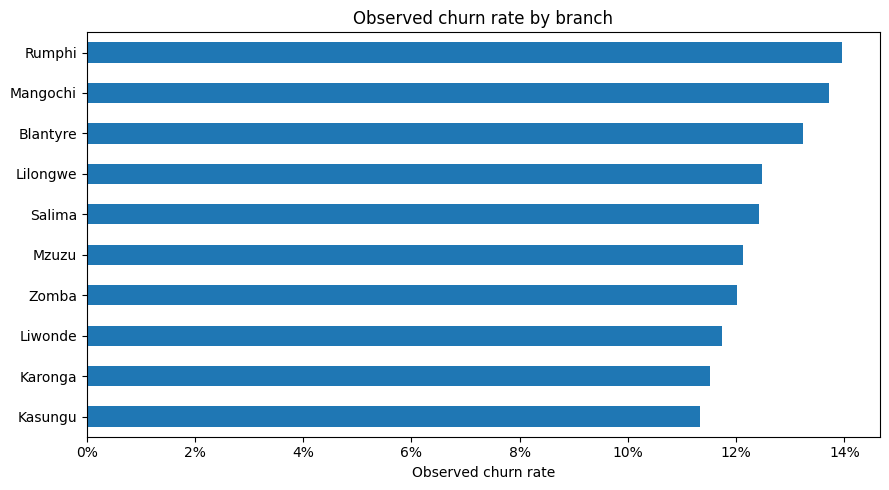

In [16]:
branch_summary = (
    customers.groupby("Branch_Location", observed=True)
    .agg(Customers=("Customer_ID", "nunique"), Churn_Rate=("Churn", "mean"))
    .sort_values("Churn_Rate", ascending=False)
)
display(branch_summary.style.format({
    "Customers": "{:,.0f}",
    "Churn_Rate": "{:.1%}",
}))

fig, ax = plt.subplots(figsize=(9, 5))
branch_summary["Churn_Rate"].sort_values().plot(kind="barh", ax=ax)
ax.set_title("Observed churn rate by branch")
ax.set_xlabel("Observed churn rate")
ax.set_ylabel("")
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:.0%}"))
plt.tight_layout()
plt.show()

## 5. Behavioural signals associated with churn

The next views explore behavioural dimensions that are relevant to customer retention. Group-level differences are associations in this generated cohort; they do not demonstrate causation.

,Customers,Churn_Rate
Recency_Band,,
0–7 days,"4,850",7.3%
8–30 days,"8,773",10.2%
31–90 days,"5,691",17.1%
91–180 days,665,39.7%
180+ days,21,76.2%


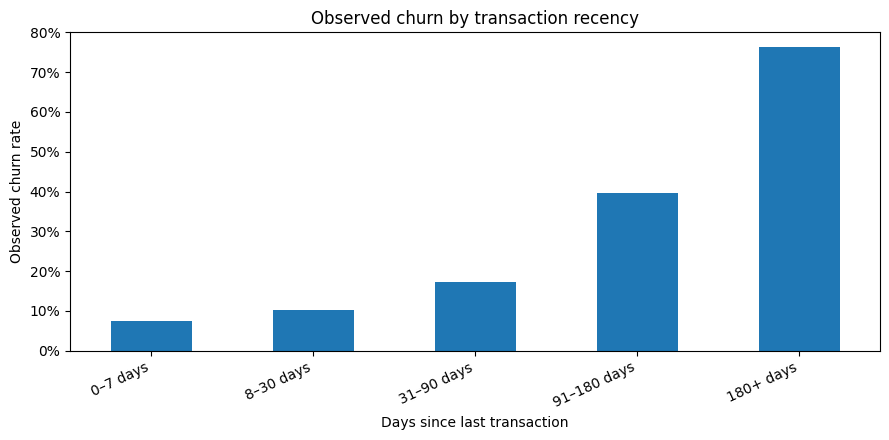

In [17]:
customers["Recency_Band"] = pd.cut(
    customers["Days_Since_Last_Transaction"],
    bins=[-1, 7, 30, 90, 180, np.inf],
    labels=["0–7 days", "8–30 days", "31–90 days", "91–180 days", "180+ days"],
)
recency_summary = (
    customers.groupby("Recency_Band", observed=True)
    .agg(Customers=("Customer_ID", "nunique"), Churn_Rate=("Churn", "mean"))
)
display(recency_summary.style.format({
    "Customers": "{:,.0f}",
    "Churn_Rate": "{:.1%}",
}))

fig, ax = plt.subplots(figsize=(9, 4.5))
recency_summary["Churn_Rate"].plot(kind="bar", ax=ax)
ax.set_title("Observed churn by transaction recency")
ax.set_xlabel("Days since last transaction")
ax.set_ylabel("Observed churn rate")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:.0%}"))
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

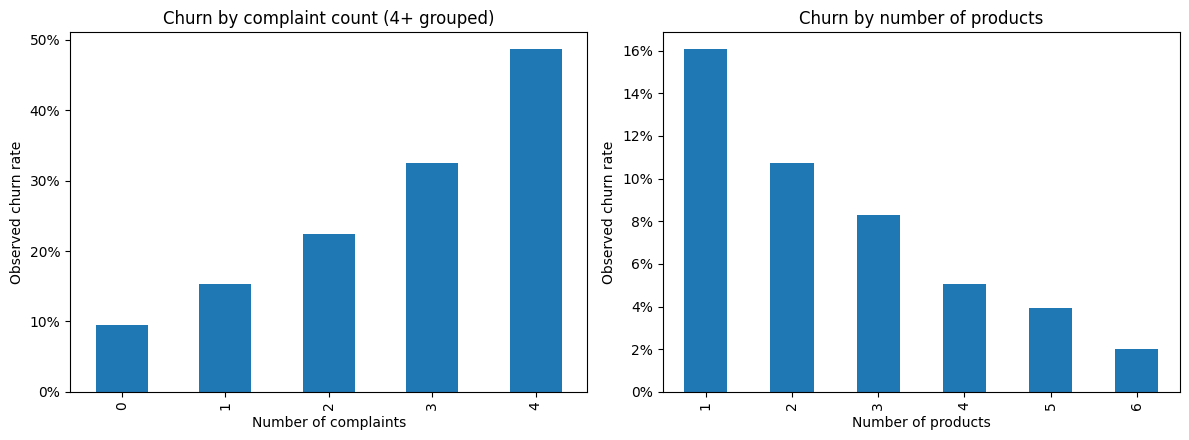

In [18]:
complaint_summary = (
    customers.assign(Complaint_Band=customers["Number_of_Complaints"].clip(upper=4))
    .groupby("Complaint_Band", observed=True)
    .agg(Customers=("Customer_ID", "nunique"), Churn_Rate=("Churn", "mean"))
)
product_summary = (
    customers.groupby("Number_of_Products", observed=True)
    .agg(Customers=("Customer_ID", "nunique"), Churn_Rate=("Churn", "mean"))
)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
complaint_summary["Churn_Rate"].plot(kind="bar", ax=axes[0])
axes[0].set_title("Churn by complaint count (4+ grouped)")
axes[0].set_xlabel("Number of complaints")
axes[0].set_ylabel("Observed churn rate")
axes[0].yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:.0%}"))

product_summary["Churn_Rate"].plot(kind="bar", ax=axes[1])
axes[1].set_title("Churn by number of products")
axes[1].set_xlabel("Number of products")
axes[1].set_ylabel("Observed churn rate")
axes[1].yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:.0%}"))
plt.tight_layout()
plt.show()

### Interpretation guardrail

A pattern can be useful for prioritisation without being causal. For example, complaints and inactivity may be associated with churn, but the analysis does not establish that reducing a complaint count or sending a message will prevent churn. Intervention effectiveness requires controlled testing.

## 6. Model governance: candidate comparison

Candidate models are compared on a validation split drawn from the training partition. The final test set is not used for candidate selection. The current operating candidate is a recall-oriented starting point; the final economic choice should reflect intervention costs and relationship-team capacity.

In [19]:
comparison_records = model_metadata.get("model_comparison", [])
if comparison_records:
    comparison = pd.DataFrame(comparison_records)
    display(comparison)
else:
    print("Candidate comparison is not present in this model bundle.")

print("Operating candidate:", model_metadata.get("selected_model", "not recorded"))
print("Selection rationale:", model_metadata.get("model_selection_rationale", "not recorded"))

,model,accuracy,precision,recall,f1,specificity,balanced_accuracy,roc_auc,average_precision,log_loss,brier_score
0,baseline,0.874667,0.000000,0.000000,0.000000,1.000000,0.500000,0.500000,0.125333,4.517471,0.125333
1,logistic,0.683667,0.235457,0.678191,0.349554,0.684451,0.681321,0.745729,0.341655,0.589635,0.202898
2,random_forest,0.771000,0.267564,0.476064,0.342584,0.813262,0.644663,0.730722,0.296499,0.523515,0.171994


Operating candidate: logistic
Selection rationale: Logistic Regression is retained as the initial operating candidate because recall is prioritised for retention screening. Candidate validation metrics remain visible; the final operating choice should be revisited using intervention costs and team capacity.


## 7. Independent held-out test performance

The metrics below are loaded from the current model bundle. They are not copied from an earlier notebook run. The held-out prediction file contains the test cohort and is kept separate from the full-population portfolio scores.

In [20]:
test_metrics = model_metadata.get("test_metrics", {})
if test_metrics:
    metrics_table = pd.DataFrame(
        [{"Metric": key.replace("_", " ").title(), "Value": value} for key, value in test_metrics.items()]
    )
    display(metrics_table.style.format({"Value": "{:.4f}"}))
else:
    print("No test metrics found in the saved model metadata.")

print(f"Test prediction rows: {len(test_predictions):,}")
print(f"Observed churn rate in test cohort: {test_predictions['Actual_Churn'].mean():.2%}")

,Metric,Value
0,Accuracy,0.8804
1,Precision,0.7164
2,Recall,0.0766
3,F1,0.1383
4,Specificity,0.9957
5,Balanced Accuracy,0.5361
6,Roc Auc,0.7365
7,Average Precision,0.3475
8,Log Loss,0.3312
9,Brier Score,0.0972


Test prediction rows: 5,000
Observed churn rate in test cohort: 12.54%


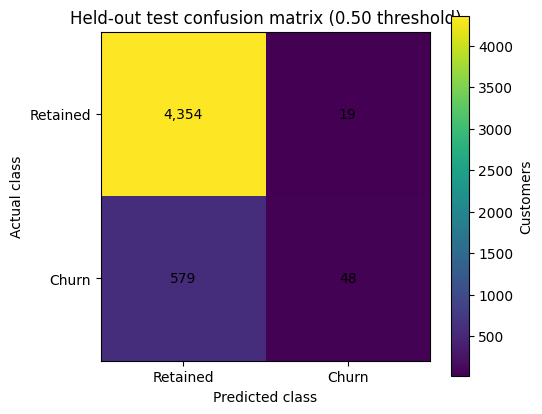

In [21]:
confusion = np.asarray(model_metadata.get("test_confusion_matrix", []))
if confusion.shape == (2, 2):
    fig, ax = plt.subplots(figsize=(5.5, 4.5))
    image = ax.imshow(confusion)
    ax.set_title("Held-out test confusion matrix (0.50 threshold)")
    ax.set_xlabel("Predicted class")
    ax.set_ylabel("Actual class")
    ax.set_xticks([0, 1], labels=["Retained", "Churn"])
    ax.set_yticks([0, 1], labels=["Retained", "Churn"])
    for (row, col), value in np.ndenumerate(confusion):
        ax.text(col, row, f"{value:,}", ha="center", va="center")
    fig.colorbar(image, ax=ax, label="Customers")
    plt.tight_layout()
    plt.show()
else:
    print("Confusion matrix is not available in the saved model metadata.")

## 8. Risk-band validation on the held-out test cohort

A useful risk band should separate observed outcomes in the held-out test cohort. This is a validation check, not a guarantee about an individual customer.

,Customers,Observed_Churn_Rate,Mean_Score
Risk_Band,,,
Low Risk,"4,761",10.6%,0.109
Medium Risk,219,47.5%,0.425
High Risk,20,80.0%,0.786


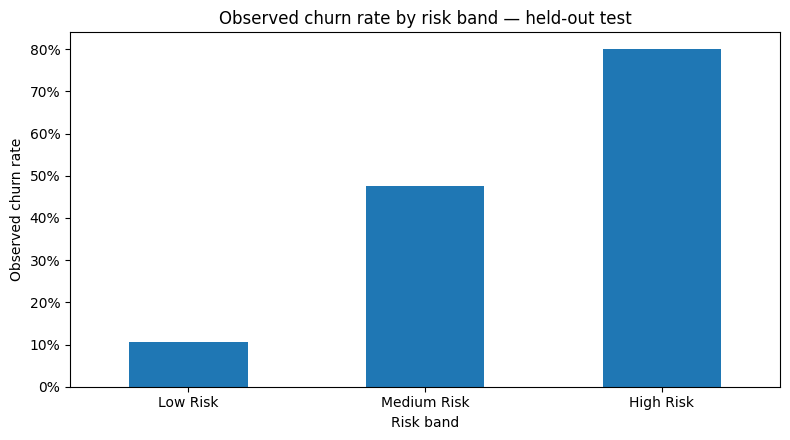

In [22]:
risk_order = ["Low Risk", "Medium Risk", "High Risk"]
risk_summary = (
    test_predictions.groupby("Risk_Band", observed=True)
    .agg(
        Customers=("Customer_ID", "nunique"),
        Observed_Churn_Rate=("Actual_Churn", "mean"),
        Mean_Score=("Churn_Probability", "mean"),
    )
    .reindex(risk_order)
)
display(risk_summary.style.format({
    "Customers": "{:,.0f}",
    "Observed_Churn_Rate": "{:.1%}",
    "Mean_Score": "{:.3f}",
}))

fig, ax = plt.subplots(figsize=(8, 4.5))
risk_summary["Observed_Churn_Rate"].plot(kind="bar", ax=ax)
ax.set_title("Observed churn rate by risk band — held-out test")
ax.set_xlabel("Risk band")
ax.set_ylabel("Observed churn rate")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:.0%}"))
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 9. Probability calibration

Discrimination and calibration answer different questions. A model can rank customers reasonably well while its probability estimates remain too high or too low. The production pipeline uses sigmoid calibration, and the independent test cohort is used to assess the resulting probability quality.

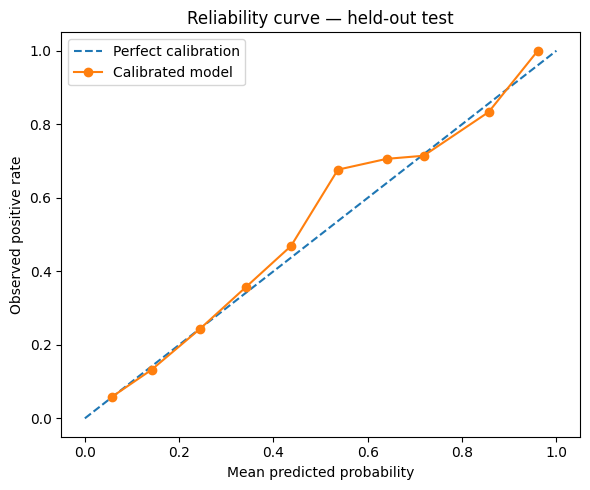

Expected calibration error (ECE): 0.0059


In [23]:
calibration = model_metadata.get("calibration_curve", {})
ece = model_metadata.get("calibration_ece")

if calibration and all(key in calibration for key in ["prob_true", "prob_pred"]):
    prob_true = np.asarray(calibration["prob_true"])
    prob_pred = np.asarray(calibration["prob_pred"])
    fig, ax = plt.subplots(figsize=(6, 5))
    ax.plot([0, 1], [0, 1], linestyle="--", label="Perfect calibration")
    ax.plot(prob_pred, prob_true, marker="o", label="Calibrated model")
    ax.set_title("Reliability curve — held-out test")
    ax.set_xlabel("Mean predicted probability")
    ax.set_ylabel("Observed positive rate")
    ax.legend()
    plt.tight_layout()
    plt.show()
else:
    print("Calibration curve is not available in the saved model metadata.")

if ece is not None:
    print(f"Expected calibration error (ECE): {float(ece):.4f}")
    if float(ece) >= 0.10:
        print("Governance caution: use scores primarily for relative ranking, not precise individual probabilities.")
else:
    print("ECE is not available in the saved model metadata.")

## 10. Threshold and capacity decisions

Threshold scenarios are calculated on the validation subset of the training data. They are decision-support evidence and are not re-optimised on the independent test set.

In [24]:
threshold_meta = model_metadata.get("threshold_analysis", {})
if threshold_meta:
    threshold_table = pd.DataFrame(threshold_meta)
    display(threshold_table)
else:
    print("Validation threshold analysis is not present in the saved model metadata.")

capacity_meta = model_metadata.get("capacity_analysis", {})
if capacity_meta:
    capacity_table = pd.DataFrame(capacity_meta)
    display(capacity_table)
else:
    print("Capacity analysis is not present in the saved model metadata.")

,threshold,precision,recall,f1,true_positives,false_positives,false_negatives,customers_flagged,share_flagged
0,0.10,0.203311,0.816489,0.325557,307,1203,69,1510,0.503333
1,0.15,0.253641,0.555851,0.348333,209,615,167,824,0.274667
2,0.20,0.324034,0.401596,0.358670,151,315,225,466,0.155333
3,0.25,0.407273,0.297872,0.344086,112,163,264,275,0.091667
4,0.30,0.475676,0.234043,0.313725,88,97,288,185,0.061667
5,0.35,0.512821,0.159574,0.243408,60,57,316,117,0.039000
6,0.40,0.571429,0.106383,0.179372,40,30,336,70,0.023333
7,0.45,0.588235,0.079787,0.140515,30,21,346,51,0.017000
8,0.50,0.705882,0.063830,0.117073,24,10,352,34,0.011333
9,0.55,0.750000,0.047872,0.090000,18,6,358,24,0.008000


,capacity,share_of_customers,precision,recall,f1,true_positives,false_positives,false_negatives,min_probability
0,100,0.02,0.680000,0.108453,0.187070,68,32,559,0.435088
1,500,0.10,0.386000,0.307815,0.342502,193,307,434,0.250540
2,1000,0.20,0.294000,0.468900,0.361401,294,706,333,0.180851
3,1500,0.30,0.253333,0.606061,0.357311,380,1120,247,0.143935
4,2000,0.40,0.218000,0.695375,0.331938,436,1564,191,0.119406


## 11. Portfolio scoring is not test evaluation

The full-population score file is designed for portfolio monitoring and retention prioritisation. It may include customers used to fit the model. Do not calculate or report independent model-performance metrics from this file.

The merge below adds customer context for exploration only. It does not change the population's evaluation status.

In [25]:
portfolio_view = portfolio_scores.merge(
    customers,
    on="Customer_ID",
    how="left",
    validate="one_to_one",
)

assert len(portfolio_view) == len(portfolio_scores)
print(f"Portfolio score records: {len(portfolio_view):,}")
print("Risk distribution:")
display(
    portfolio_view["Risk_Band"]
    .value_counts(dropna=False)
    .rename_axis("Risk band")
    .to_frame("Customers")
)

portfolio_priority = portfolio_view.sort_values("Churn_Probability", ascending=False)
display(portfolio_priority[
    ["Customer_ID", "Churn_Probability", "Risk_Band", "Customer_Segment",
     "Branch_Location", "Days_Since_Last_Transaction", "Number_of_Complaints"]
].head(15))

Portfolio score records: 20,000
Risk distribution:


,Customers
Risk band,
Low Risk,19032
Medium Risk,898
High Risk,70


,Customer_ID,Churn_Probability,Risk_Band,Customer_Segment,Branch_Location,Days_Since_Last_Transaction,Number_of_Complaints
4443,CUST-0004444,0.985113,High Risk,Retail,Blantyre,294,2
3479,CUST-0003480,0.968710,High Risk,Retail,Lilongwe,207,3
6286,CUST-0006287,0.963639,High Risk,Salary Account,Lilongwe,251,1
8276,CUST-0008277,0.961930,High Risk,Retail,Zomba,238,2
16847,CUST-0016848,0.934952,High Risk,Salary Account,Blantyre,202,2
7515,CUST-0007516,0.934401,High Risk,Student/Youth,Kasungu,179,2
1520,CUST-0001521,0.925145,High Risk,Salary Account,Blantyre,215,1
10112,CUST-0010113,0.901327,High Risk,Retail,Mangochi,210,0
8427,CUST-0008428,0.892354,High Risk,Retail,Blantyre,154,3
2788,CUST-0002789,0.868315,High Risk,Salary Account,Liwonde,159,2


## 12. From analytics to retention operations

The Streamlit Command Centre translates portfolio scoring into operational workspaces:

- Retention Prioritisation builds a capacity-constrained ranked queue.
- Campaign Studio applies campaign filters, plans contact and allocates the queue across relationship managers.
- Case Management tracks status, ownership, contact details and overdue follow-ups.

Campaign and case records are imported/exported as CSV files. They are not currently persisted in a shared CRM or multi-user database. Human review remains necessary before customer-facing action.

## 13. Reproducibility and final checklist

To regenerate the artefacts from the repository root:

```bash
python scripts/generate_dataset.py
python scripts/train_pipeline.py
pytest tests/ -v
streamlit run dashboard/streamlit_command_centre.py
```

For a controlled refresh in GitHub, use the manual [production model refresh workflow](https://github.com/MkandawireChico/-Banking-Customer-Churn-Analysis-and-Prediction/actions/workflows/refresh-production-model.yml).

### Interpretation and responsible-use limits

- The cohort and churn outcomes are synthetic.
- Group differences are associations, not causal effects.
- The held-out test set is the source for independent model evaluation.
- The full-population score file is for operational prioritisation only.
- Threshold choice should reflect intervention costs and available capacity.
- Validate privacy, fairness, calibration and drift on authorised representative data before any real-world use.
- A churn score must not independently trigger denial of service, account closure or punitive treatment.